# Decision Tree on TF-IDF

This notebook trains a single decision tree on the same TF-IDF features and train/test split as the Logistic Regression baseline. A shallow tree can be read in full, so it is a useful contrast to the Random Forest, and the post-hoc methods below show how far they agree with what the tree visibly does.

Because the tree can be read in full, PDP and ICE are not used (see the note before Section 8). The explanation steps are global importance (PFI / TreeSHAP) → individual decisions (LIME / SHAP).

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("punkt")
nltk.download("punkt_tab")

from IPython.display import display
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, recall_score, accuracy_score
)
from sklearn.inspection import PartialDependenceDisplay

from lime.lime_text import LimeTextExplainer
from lime.submodular_pick import SubmodularPick
import shap

from preprocessing import (
    preprocess_text, get_tfidf_features,
    get_train_test_split, select_top_k_terms, get_split_tfidf, RANDOM_STATE
)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
c:\Users\ADMIN\Desktop\XDS_project\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load Cleaned Dataset

In [2]:
df = pd.read_csv("Dataset/fake_news_dataset_cleaned.csv")
df[["title", "text", "label", "label_encoded"]].head()

,title,text,label,label_encoded
0,Foreign Democrat final.,more tax development both store agreement lawy...,real,0
1,To offer down resource great point.,probably guess western behind likely next inve...,fake,1
2,Himself church myself carry.,them identify forward present success risk sev...,fake,1
3,You unit its should.,phone which item yard Republican safe where po...,fake,1
4,Billion believe employee summer how.,wonder myself fact difficult course forget exa...,fake,1


## 3. Text Preprocessing

In [3]:
df["full_text"] = df["title"] + " " + df["text"]
df["processed_text"] = df["full_text"].apply(preprocess_text)
df[["full_text", "processed_text"]].head()

,full_text,processed_text
0,Foreign Democrat final. more tax development b...,foreign democrat final tax development store a...
1,To offer down resource great point. probably g...,offer resource great point probably guess west...
2,Himself church myself carry. them identify for...,church carry identify forward present success ...
3,You unit its should. phone which item yard Rep...,unit phone item yard republican safe police id...
4,Billion believe employee summer how. wonder my...,billion believe employee summer wonder fact di...


Quick check: compare one raw vs. processed example side by side.

In [4]:
print("RAW:\n", df["full_text"].iloc[0][:300])
print("\nPROCESSED:\n", df["processed_text"].iloc[0][:300])

RAW:
 Foreign Democrat final. more tax development both store agreement lawyer hear outside continue reach difference yeah figure your power fear identify there protect security great national nothing fast story why late nearly bit cost tough since question to power almost future young conference behind a

PROCESSED:
 foreign democrat final tax development store agreement lawyer hear outside continue reach difference yeah figure power fear identify protect security great national nothing fast story late nearly bit cost tough since question power almost future young conference behind ahead building teach million b


## 4. TF-IDF Vectorization

In [5]:
X, y, tfidf = get_tfidf_features(df)

print("TF-IDF matrix shape:", X.shape)

TF-IDF matrix shape: (20000, 867)


## 5. Train/Test Split

In [6]:
X_train, X_test, y_train, y_test, tfidf = get_split_tfidf(df)
feature_names = tfidf.get_feature_names_out()

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("\nTrain class balance:\n", y_train.value_counts(normalize=True).round(3))
print("\nTest class balance:\n", y_test.value_counts(normalize=True).round(3))

Train shape: (16000, 867)
Test shape: (4000, 867)

Train class balance:
 label_encoded
1    0.503
0    0.497
Name: proportion, dtype: float64

Test class balance:
 label_encoded
1    0.503
0    0.497
Name: proportion, dtype: float64


## 6. Train Decision Tree

We use a single decision tree limited to a depth of 3, with at least 50 training articles in every leaf, so that no rule rests on a handful of chance cases. A tree of this size has at most 7 decision points and 8 leaves, in line with the 7 ± 2 limit on human working memory, so a reader can follow any prediction from the top question to its answer and can hold the whole tree in mind at once. This matters when the model is audited, because the model should stay simulatable: an auditor can take an article, answer each question in turn, reach the same prediction the model made, and check every rule for anything unreasonable. A deeper tree quickly makes this impossible, since the size of a tree roughly doubles with each extra level. A depth of 5 allows up to 31 decision points, a depth of 7 up to 127, and a depth of 10 up to 1,023, which is far more than a person can read, remember or check, even though each single prediction would still follow a path of only 5, 7 or 10 questions. The cost of choosing a depth of 3 is flexibility: the tree can only ask a few questions, so it can use only a handful of the 867 terms.

In [7]:
dt = DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, random_state=RANDOM_STATE)
dt.fit(X_train, y_train)
y_pred = dt.predict(X_test)

### 6.1 The Tree Itself

Unlike the Random Forest, the whole model fits on one page. The text version and the diagram below show every question the tree asks and what it predicts at the end. In each box, the first line is the question asked of an article (the TF-IDF weight of a term compared with a cutoff), and the box also shows the share of training articles that reached it and the class predicted there.

In [8]:
used_idx = np.unique(dt.tree_.feature[dt.tree_.feature >= 0])
print("Terms used by the tree:", list(feature_names[used_idx]))
print()
print(export_text(dt, feature_names=list(feature_names), decimals=3))

Terms used by the tree: ['environmental', 'good', 'purpose', 'save', 'significant', 'wrong']

|--- good <= 0.065
|   |--- significant <= 0.057
|   |   |--- wrong <= 0.061
|   |   |   |--- class: 0
|   |   |--- wrong >  0.061
|   |   |   |--- class: 1
|   |--- significant >  0.057
|   |   |--- environmental <= 0.063
|   |   |   |--- class: 1
|   |   |--- environmental >  0.063
|   |   |   |--- class: 0
|--- good >  0.065
|   |--- save <= 0.065
|   |   |--- purpose <= 0.066
|   |   |   |--- class: 1
|   |   |--- purpose >  0.066
|   |   |   |--- class: 1
|   |--- save >  0.065
|   |   |--- class: 0



The tree uses six terms (environmental, good, purpose, save, significant and wrong) and asks at most three questions about any article. Each question compares the TF-IDF weight of one term in the article with a small cutoff between 0.057 and 0.066. The first question is about good. If the article has little or none of it, the tree asks about significant: with little significant it predicts fake only when wrong is present, and with more significant it predicts fake unless environmental is also present. If the article has more good, the tree asks about save: with little save it predicts fake, and with more save it predicts real. The question about purpose does not change any prediction, because both of its leaves predict fake, so it only changes how confident the tree is. The tree has 6 decision points and 7 leaves, one fewer of each than the maximum for a depth of 3, because the branch ending in save stops after a single question.

The terms are ordinary words, and none is an obvious marker of fabricated reporting. Good, significant and wrong are also words that pointed toward fake in the baseline, so the tree finds part of what the logistic regression found. The whole model can be checked by hand in a few seconds, which is its main strength, but whether these rules reflect a real difference between fake and real articles depends on the performance results below.

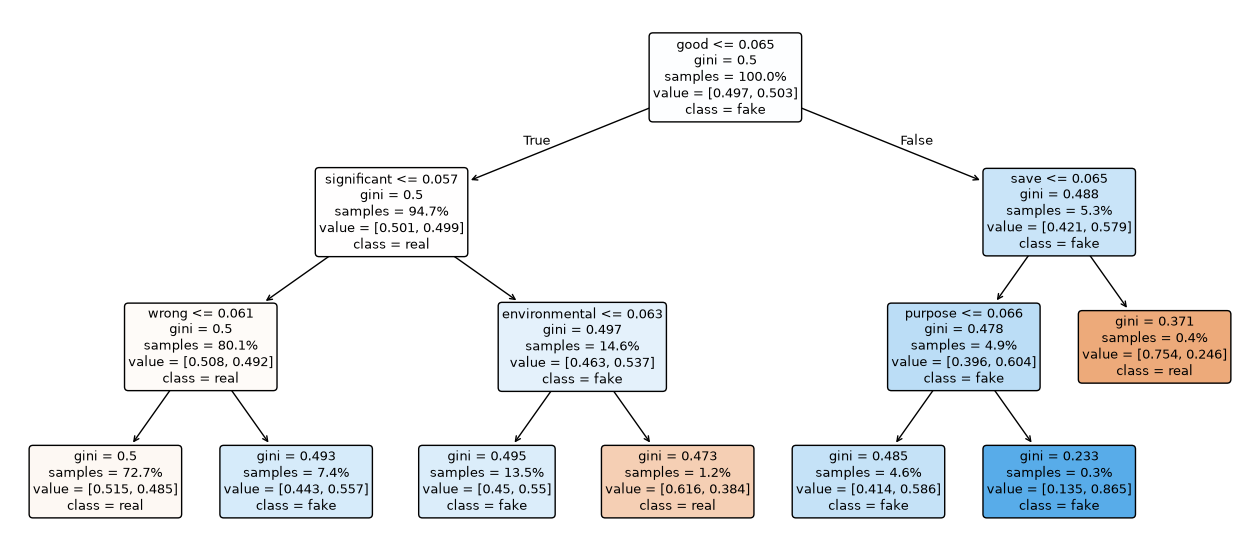

In [9]:
plt.figure(figsize=(16, 7))
plot_tree(dt, feature_names=list(feature_names), class_names=["real", "fake"],
          filled=True, rounded=True, proportion=True, fontsize=9, precision=3)
plt.show()

Each box in the diagram shows the question asked of an article, the share of training articles that reach it (samples), the share of real and fake articles among them (value, in the order real then fake), and the class the tree predicts there. Gini measures how mixed a box is, from 0 for a box with only one class to 0.5 for an even split. Blue boxes lean toward fake and orange boxes toward real, and a darker color means a stronger lean. The root is an even split of 49.7% real and 50.3% fake, and almost every article (94.7%) goes left because it has little or none of the word good.

The diagram shows how little the tree separates the two classes. Five of the seven leaves have a gini between 0.47 and 0.5, which means they are almost evenly mixed, and the largest leaf, which holds 72.7% of all articles, contains 51.5% real and 48.5% fake, so predicting real for those articles is only slightly better than a coin flip. The only clear leanings are in two very small leaves: the leaf for articles with more purpose holds 0.3% of articles and is 86.5% fake, and the leaf for articles with more save holds 0.4% and is 75.4% real. Together they cover less than 1% of articles, and because they rest on so few articles and the tree searched hundreds of terms for its best splits, they may partly be chance. Overall, the tree labels about three quarters of the training articles real (the three orange leaves hold 74.3%) and only about a quarter fake, so it will miss many fake articles, which the next section checks.

### 6.2 Why Not a Deeper Tree?

In [10]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for depth in [3, 5, 7, 10]:
    cv_model = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=50, random_state=RANDOM_STATE)
    cv_pred = cross_val_predict(cv_model, X_train, y_train, cv=skf)
    rows.append({
        "max_depth": depth,
        "max_splits": 2**depth - 1,
        "max_leaves": 2**depth,
        "cv_accuracy": round(accuracy_score(y_train, cv_pred), 3),
    })
pd.DataFrame(rows)

,max_depth,max_splits,max_leaves,cv_accuracy
0,3,7,8,0.502
1,5,31,32,0.503
2,7,127,128,0.500
3,10,1023,1024,0.497


Cross-validated accuracy on the training set stays between 0.497 and 0.503 at every depth, which is no better than always predicting “fake” (0.503). The larger trees are no better at telling fake from real, so the extra splits would only make the tree harder to audit. This also confirms the baseline’s finding (permutation test p = 0.158): at any size, the tree finds no usable signal in the text.

## 7. Validate Predictive Performance

In [11]:
print(classification_report(y_test, y_pred, target_names=["real", "fake"]))

recall_fake = recall_score(y_test, y_pred, pos_label=1)
accuracy = accuracy_score(y_test, y_pred)
train_recall = recall_score(y_train, dt.predict(X_train), pos_label=1)

print(f"Fake-class recall (test):  {recall_fake:.4f}")
print(f"Fake-class recall (train): {train_recall:.4f}")
print(f"Accuracy (test): {accuracy:.4f}")
print(f"Share of test articles predicted fake: {y_pred.mean():.3f}")

              precision    recall  f1-score   support

        real       0.51      0.75      0.61      1989
        fake       0.53      0.28      0.37      2011

    accuracy                           0.51      4000
   macro avg       0.52      0.52      0.49      4000
weighted avg       0.52      0.51      0.49      4000

Fake-class recall (test):  0.2810
Fake-class recall (train): 0.2884
Accuracy (test): 0.5140
Share of test articles predicted fake: 0.266


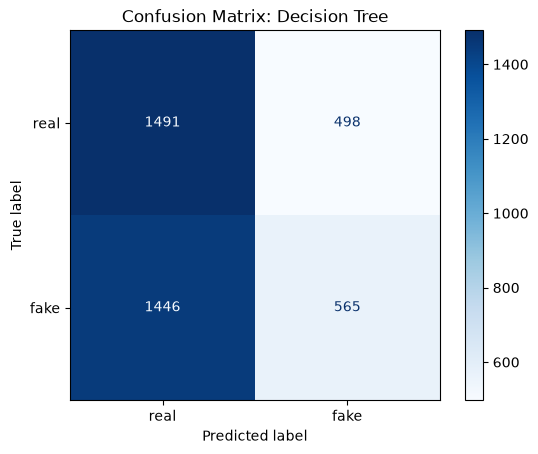

In [12]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["real", "fake"]).plot(cmap="Blues")
plt.title("Confusion Matrix: Decision Tree")
plt.show()

- True Positive, correctly caught fake news article: 565
- False Negative, fake news article predicted as real: 1,446
- False Positive, real article predicted as fake: 498
- True Negative, correctly identified real article: 1,491

The tree catches only 28.1% of fake articles (recall = 0.2810) and misses 1,446 of the 2,011, which is 473 more than the baseline (973). It labels just 26.6% of test articles as fake. That is why it gets 75% of real articles right: it calls most articles real. Accuracy is 51.4%, close to the 50.3% you get by always predicting “fake.” Cross-validation in Section 6.2 put the same tree at 50.2%, so the slightly higher test number is most likely a favourable split.

The low recall does not mean the tree is a much worse model than the baseline. Both are at chance, and the difference comes from a single leaf. 72.7% of articles land in a leaf that is 51.5% real, so the tree labels all of them real. That leaf holds about 70% of all fake articles. If it had tipped 1.5 points the other way, recall would jump above 0.9 with the same near-chance accuracy. This is why recall has to be read together with accuracy and precision.

Training recall (0.2884) almost matches test recall (0.2810), so the problem is not overfitting. For a trust-and-safety reviewer, whose costliest error is a fake article slipping through, the model is not usable: nearly three in four fake articles get through.

In [13]:
X_test_dense = X_test.toarray().astype(np.float32)

rng = np.random.RandomState(RANDOM_STATE)
sample_idx = rng.choice(X_test_dense.shape[0], size=500, replace=False)
X_sample = X_test_dense[sample_idx] 

The decision tree is fully readable. For any article, we can trace its exact path through the rules in Section 6.1 and see precisely why the tree made its prediction. No post-hoc method can improve on this.

For this reason, PDP and ICE are not needed. Each term is used in only one split with one cutoff, so its PDP would be a single step at 0.06 or 0.07, and each article’s ICE curve would be a single step or flat line. All of this, including how terms interact, can already be read from the tree. These methods would also be misleading with TF-IDF features. They change one term’s weight while keeping the rest of the article the same, which creates articles that could not exist.

PFI, TreeSHAP and LIME are still used, because they show things the tree does not. The tree shows which questions are asked, but not how much each one matters on real articles. PFI measures how much each term affects Fake-class recall, and TreeSHAP shows how much each term moves the predicted probability.

Since we know the true rules, we can also check whether these methods report them correctly. If they do, we can trust them more on the Random Forest, whose rules cannot be read.

## 8. Global Importance (PFI and TreeSHAP)

Across the whole test set, which of the tree's six terms matter most, and how much?

### 8.1 Permutation Feature Importance (PFI)

Each of the six terms used by the tree is shuffled across the test articles, and we measure how much Fake-class recall drops, averaged over 5 repeats. Shuffling any other term cannot change a prediction, so those terms are left out.

A large drop means the tree relies on that term to catch fake articles. A drop near zero means the term barely affects recall. A negative drop means recall improves when the term is shuffled, so the rule it is part of does not help on the test set.

In [14]:
def permutation_recall_drop(model, X_dense, y_true, col_indices, n_repeats=5, seed=RANDOM_STATE):
    rng = np.random.RandomState(seed)
    base = recall_score(y_true, model.predict(X_dense), pos_label=1)
    rows = []
    for col in col_indices:
        original = X_dense[:, col].copy()
        drops = []
        for _ in range(n_repeats):
            X_dense[:, col] = rng.permutation(original)
            drops.append(base - recall_score(y_true, model.predict(X_dense), pos_label=1))
        X_dense[:, col] = original
        rows.append((feature_names[col], np.mean(drops), np.std(drops)))
    result = pd.DataFrame(rows, columns=["term", "mean_recall_drop", "std"])
    return base, result.sort_values("mean_recall_drop", ascending=False)

base_recall, pfi_df = permutation_recall_drop(dt, X_test_dense, y_test, used_idx)
print(f"Recall before shuffling: {base_recall:.4f}")
pfi_df.head(7)

Recall before shuffling: 0.2810


,term,mean_recall_drop,std
1,good,0.003282,0.002643
4,significant,0.002984,0.004852
0,environmental,0.002089,0.001923
2,purpose,0.000000,0.000000
5,wrong,-0.001691,0.003059
3,save,-0.002387,0.000856


Shuffling any of the six terms barely changes how many fake articles the tree catches. The largest drop is for good, the first question in the tree, at 0.0033. That is only about 7 of the 2,011 fake test articles. significant (0.0030) and environmental (0.0021) come next. For significant and wrong, the variation between repeats is larger than the drop itself, so their effect cannot be told apart from zero. purpose has a drop of exactly zero. This matches the tree: both of its leaves predict fake, so changing purpose can never change a prediction. wrong and save have negative drops, meaning recall improves slightly when they are shuffled. For save, this is because a high save weight sends articles to the real leaf. Shuffling takes that route away from the fake articles that had it, so they are labelled fake instead. For wrong, its rule simply does not pick out fake articles on the test set better than chance.

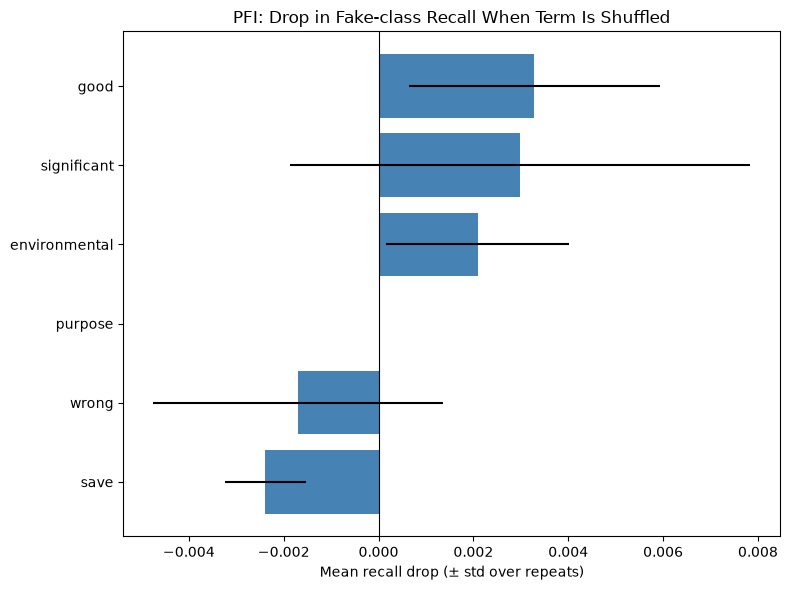

In [15]:
top_pfi = pfi_df.head(7).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top_pfi["term"], top_pfi["mean_recall_drop"], xerr=top_pfi["std"], color="steelblue")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("PFI: Drop in Fake-class Recall When Term Is Shuffled")
plt.xlabel("Mean recall drop (± std over repeats)")
plt.tight_layout()
plt.show()

The plot shows the same picture. Every bar is tiny compared with the tree’s recall of 0.2805. Even good, the most important term, accounts for only about 1.2% of it. The error bars of significant and wrong cross zero, so these two terms have no clear effect. good and environmental only just clear zero, and save sits clearly below it. The order roughly follows the tree. good, which every article passes through, comes first, and the terms asked later come after. Overall, PFI confirms what Section 7 found. No single term carries much signal, so removing the information in any one of them changes almost nothing.

### 8.2 TreeSHAP (global view)

SHAP splits each prediction into a contribution from each term. Starting from the tree's average predicted probability of fake, the contributions add up exactly to the probability the tree gives that article. For trees, TreeSHAP calculates these values exactly rather than estimating them.

The values are computed for 200 test articles, the same sample size used in the other notebooks, and then averaged to show which terms matter most overall.

In [16]:
explainer_shap = shap.TreeExplainer(dt)
X_shap = X_sample[:200]

sv = explainer_shap.shap_values(X_shap, check_additivity=False)

# SHAP's output format differs by version; extract values for the FAKE class (index 1)
if isinstance(sv, list):
    sv_fake = sv[1]
elif sv.ndim == 3:
    sv_fake = sv[:, :, 1]
else:
    sv_fake = sv

ev = explainer_shap.expected_value
base_value = ev[1] if np.ndim(ev) > 0 else ev
print("SHAP values shape:", sv_fake.shape)

SHAP values shape: (200, 867)


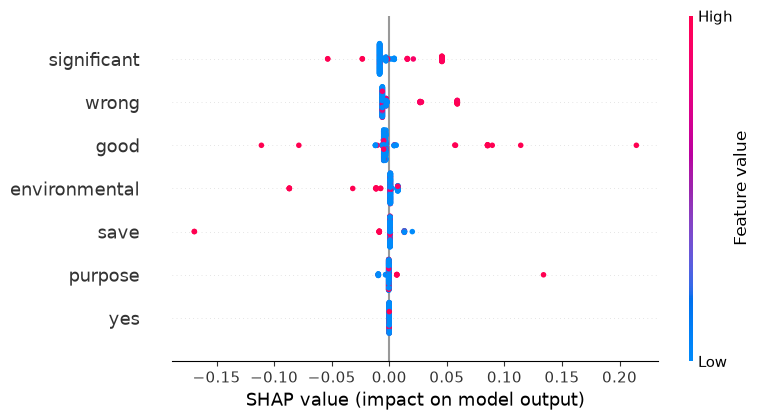

In [17]:
shap.summary_plot(sv_fake, X_shap, feature_names=list(feature_names), max_display=7)

Each dot is one of the 200 test articles. Its position shows how much a term moved that article's predicted probability of fake away from the average of 0.503. Its color shows the term's weight in the article: red for high, blue for low. Only the six terms used by the tree have any spread. The seventh row, yes, is shown only because the plot lists seven terms, and all its values are exactly zero, as for every other unused term. This shows TreeSHAP is reporting the tree correctly. Most dots are blue and sit close to zero, because most articles contain none of these words. The large pushes, up to about 0.2 either way, come from only a few red dots, which are the rare articles that contain these words. The directions mostly match the rules in Section 6.1. High wrong and purpose push toward fake, while high environmental and save push toward real. High good and significant can push either way, because their effect depends on which branch the article goes down next. For example, good leads toward fake unless the article also contains save.

In [18]:
shap_importance = pd.DataFrame({
    "term": feature_names,
    "mean_abs_shap": np.abs(sv_fake).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

shap_importance.head(7)

,term,mean_abs_shap
683,significant,0.012752
860,wrong,0.010736
316,good,0.010445
237,environmental,0.004125
649,save,0.003360
590,purpose,0.001728
4,account,0.000000


On average, significant, wrong and good move the predicted probability the most, by about one percentage point each. environmental, save and purpose follow, and every other term, starting with account, is exactly zero. This order differs from PFI because the two methods measure different things. SHAP measures how much a term changes the probability, while PFI measures how much it changes the final fake or real decision. purpose shows this clearly. It raises the probability to 0.865, so its SHAP value is not zero. But it never changes the predicted class, so its PFI is zero. Both methods agree on the main point: only six terms matter, and their effects are small.

## 9. Individual Decisions (LIME and SHAP)

So far we have looked at what drives the tree's predictions overall. Now we look at three single articles to see why the tree made each decision:

- a fake article the tree caught correctly,
- a fake article it missed, and
- a real article it wrongly flagged as fake.

LIME and SHAP show which words pushed each prediction toward fake or toward real. Since the tree's own path already explains each article exactly, this also lets us check whether LIME and SHAP report that path correctly.

In [19]:
explainer_lime = LimeTextExplainer(class_names=["real", "fake"], random_state=RANDOM_STATE)

def predict_proba_text(texts):
    return dt.predict_proba(tfidf.transform(texts))

test_text = df.loc[y_test.index, "processed_text"].reset_index(drop=True)
y_true_arr = y_test.reset_index(drop=True).to_numpy()
y_pred_arr = np.asarray(y_pred)
proba_fake = dt.predict_proba(X_test)[:, 1]

tp = np.where((y_true_arr == 1) & (y_pred_arr == 1))[0]
fn = np.where((y_true_arr == 1) & (y_pred_arr == 0))[0]
fp = np.where((y_true_arr == 0) & (y_pred_arr == 1))[0]

cases = {
    "True Positive (fake, caught)":      tp[np.argmax(proba_fake[tp])],
    "False Negative (fake, missed)":     fn[np.argmin(proba_fake[fn])],
    "False Positive (real, flagged)":    fp[np.argmax(proba_fake[fp])],
}

### 9.1 LIME: Word-Removal Sanity Checks

LIME removes words from one article and watches how the predicted probability changes. Three cases are inspected: a correctly caught fake article (TP), a missed fake article (FN), and a real article wrongly flagged as fake (FP). Weights are for the fake class: positive = pushes toward fake.

True Positive (fake, caught) | P(fake) = 0.865


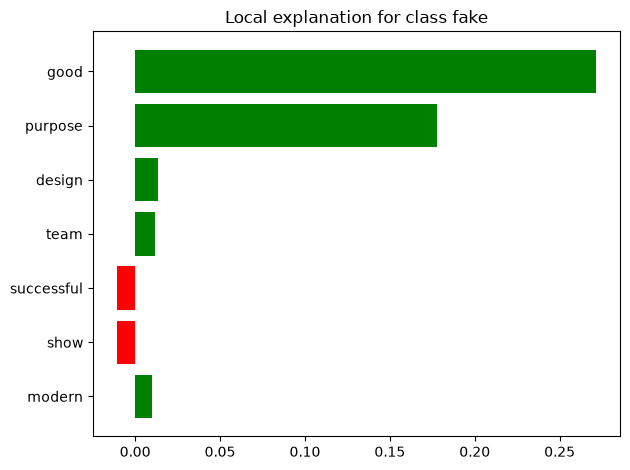

False Negative (fake, missed) | P(fake) = 0.246


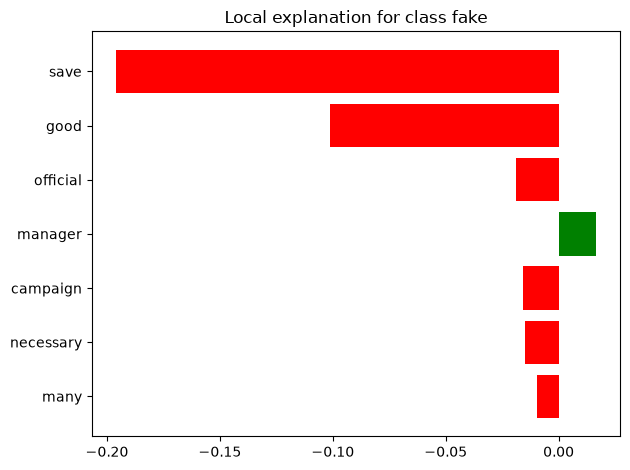

False Positive (real, flagged) | P(fake) = 0.865


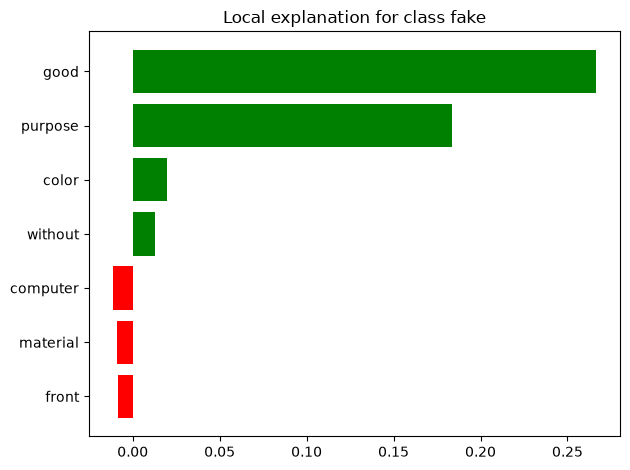

In [20]:
for name, i in cases.items():
    exp = explainer_lime.explain_instance(
        test_text.iloc[i], predict_proba_text,
        num_features=7, num_samples=1000, labels=(1,)
    )
    print(f"{name} | P(fake) = {proba_fake[i]:.3f}")
    exp.as_pyplot_figure(label=1)
    plt.tight_layout()
    plt.show()

All three articles reach very small leaves, which shows how the tree decides at its extremes.

**True Positive (P(fake) = 0.865).** The fake article contains good and purpose but not save, so it reaches the leaf with the highest probability of fake. LIME shows good (about 0.27) and purpose (about 0.18) as the words pushing toward fake. The tree also needs save to be absent, but LIME cannot show this, because it can only remove words that are in the article.

**False Negative (P(fake) = 0.246).** The fake article contains good and save, so it lands in the save leaf, which is 75.4% real. LIME shows save (about −0.20) as the main reason for the miss, followed by good (about −0.10). good pushes toward real here because it is what led the tree to the save question. This rule rests on only 0.4% of the training articles, so the miss comes from a weak pattern.

**False Positive (P(fake) = 0.865).** This real article reaches the same leaf as the True Positive and gets almost the same explanation: good (about 0.27) and purpose (about 0.18) push it toward fake. The tree is just as confident here as for the correct case, and in both cases the confidence rests on two everyday words. A reviewer could not tell a correct flag from a wrong one.

In every plot, the other five words (such as design, official and color) have weights below 0.02. The tree never uses these words, so their small bars are noise from LIME's sampling.

Note on these examples: the three articles were chosen as the most extreme cases, so they all fall into very small leaves (under 0.5% of training articles each). They are not typical. Most missed fake articles land in the largest leaf, which holds 72.7% of articles, simply because they contain none of good, significant or wrong. LIME cannot explain those misses well, because it can only remove words that are in the article, not show the effect of words that are missing. The tree diagram explains them more directly than any post-hoc method.

### 9.2 SHAP Waterfall (the missed fake article)

LIME approximates the tree around one article, while SHAP splits the tree's own prediction into exact contributions from each term. Here SHAP explains the missed fake article from 9.1, so the two methods can be compared on the same case.

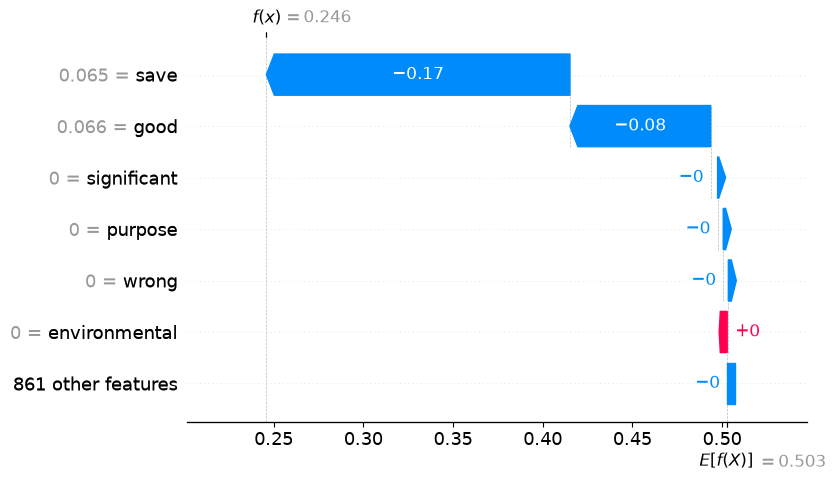

In [21]:
fn_idx = cases["False Negative (fake, missed)"]
x_fn = X_test_dense[fn_idx:fn_idx + 1]

sv_fn = explainer_shap.shap_values(x_fn, check_additivity=False)
if isinstance(sv_fn, list):
    sv_fn_fake = sv_fn[1]
elif sv_fn.ndim == 3:
    sv_fn_fake = sv_fn[:, :, 1]
else:
    sv_fn_fake = sv_fn

shap.plots.waterfall(
    shap.Explanation(
        values=sv_fn_fake[0], base_values=base_value,
        data=x_fn[0], feature_names=list(feature_names)
    ),
    max_display=7
)

The waterfall starts at 0.503, the tree's average prediction, and ends at 0.246, the probability of the save leaf. The bars add up exactly to this difference, which LIME cannot guarantee. Most of the drop comes from save (−0.17), followed by good (−0.08). good pulls the probability down here because, in this article, it is what led the tree to the save question. All other terms, including the 861 the tree never uses, contribute essentially nothing. The weights of save (0.065) and good (0.066) are only just above their cutoffs. A slightly lower weight for either word would have sent the article down a different path, so this miss depends on a very small margin. SHAP and LIME agree on the explanation: save is the main reason for the miss and good is second, with almost the same sizes in both methods. This shows LIME and SHAP both report the tree's path correctly.

## 10. Summary

The decision tree, with a depth of 3 and at least 50 articles per leaf, is small enough to read and check by hand. It uses only six everyday words: good, significant, wrong, environmental, save and purpose.

It performs at chance. Test accuracy is 0.514, and cross-validated accuracy stays at about 0.50 at every depth from 3 to 10, no better than always predicting "fake." Fake-class recall is 0.2810 (1,446 of 2,011 fake articles missed), lower than the baseline's 0.516. This reflects which side the tree's largest, nearly 50/50 leaf happens to fall on, not a weaker model. Training and test recall are almost identical, so the problem is not overfitting: the words simply carry no usable signal, which matches the baseline's permutation test.

The explanation methods agree with the tree's own rules:

- **PFI:** shuffling any term changes recall by less than 0.004, and purpose changes it by exactly zero, since both of its leaves predict fake.
- **TreeSHAP:** every unused term gets exactly zero, and even the six used terms move the probability by only about one percentage point on average.
- **LIME:** the caught fake article and the wrongly flagged real article get the same explanation, good and purpose. The missed fake article was sent to the real side by save, a rule based on only 0.4% of training articles.
- **SHAP waterfall:** it gives the same explanation for the missed article as LIME, with almost the same sizes.

Since these methods correctly report rules we can check, we can trust them more on the Random Forest, whose rules cannot be read.

For a trust-and-safety reviewer, this tree is not usable. It misses nearly three in four fake articles, and when it flags one, its confidence rests on everyday words that have nothing to do with fake reporting. Its main value is that it makes this lack of signal easy to see.